# FTPing report explorer

Interactive view over the output of `scripts/ping_sites.py`. Every day the
[workflow](.github/workflows/daily-ftp-ping.yml) writes three kinds of files under
[`reports/`](reports):

| File | Content |
| --- | --- |
| `reports/YYYY-MM-DD.jsonl` | one JSON object per endpoint check: timestamp, host, port, `up`/`down`, TCP latency, error details |
| `reports/YYYY-MM-DD-success.json` | that day's summary plus only the endpoints that answered (reruns become `-success-1.json`, `-2`, …) |
| `reports/dir/<host>.json` | anonymous-FTP root listing per reachable host: server banner, `SYST`, `FEAT`, entry metadata, size/time summary |

This notebook loads **all** of those files into pandas, prints headline tables and renders
charts (reachability per day, latency, failure reasons, listing methods, biggest roots,
common `FEAT` features, …). The rendered images are embedded in this `.ipynb` and are
**intentionally not cleaned**: committed outputs stay visible on GitHub without running anything.
After a new daily run lands, *Restart & Run All* refreshes every table and figure.

In [1]:
import glob
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
plt.rcParams.update({
    "figure.figsize": (10.5, 4.6),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.30,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
})

GREEN, RED, BLUE, ORANGE, PURPLE = "#2e7d32", "#b71c1c", "#1565c0", "#ef6c00", "#6a1b9a"

def find_reports_dir(start=None):
    """Walk upwards from `start` (default: cwd) until a directory containing `reports/` is found."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        reports = candidate / "reports"
        if reports.is_dir():
            return reports
    raise FileNotFoundError(
        "Could not locate a 'reports' directory next to the notebook or its parents. "
        "Set REPORTS = Path('/path/to/ftping/reports') manually."
    )

def human_bytes(n):
    """1234567 -> '1.2 MiB'; None/NaN -> em dash."""
    if n is None or (isinstance(n, float) and np.isnan(n)):
        return "\u2014"
    n = float(n)
    if n < 1024:
        return f"{int(n):,} B"
    for unit in ("KiB", "MiB", "GiB", "TiB", "PiB"):
        n /= 1024
        if n < 1024 or unit == "PiB":
            return f"{n:,.2f} {unit}"

REPORTS = find_reports_dir()
print(f"Reports directory: {REPORTS}")
print("Daily check files :", sorted(p.name for p in REPORTS.glob("*.jsonl")))
print("Root listings     :", len(list((REPORTS / "dir").glob("*.json"))))

Reports directory: /home/user/ftping/reports
Daily check files : ['2026-10-13.jsonl', '2026-10-14.jsonl']
Root listings     : 860


## 1 · Reachability checks — `reports/*.jsonl`

Each line of each daily file is one TCP connect attempt against one FTP endpoint.
Here every file is flattened into a single `checks` frame, so new dates are picked up
automatically on re-run.

In [2]:
rows = []
for path in sorted(glob.glob(str(REPORTS / "*.jsonl"))):
    date = Path(path).stem
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            r = json.loads(line)
            err = r.get("error") or {}
            rows.append({
                "date": date,
                "checked_at": r.get("checked_at"),
                "host": r.get("host"),
                "port": r.get("port"),
                "status": r.get("status"),
                "latency_ms": r.get("latency_ms"),
                "error_type": err.get("type"),
                "error_message": err.get("message"),
            })

checks = pd.DataFrame(rows)
checks["checked_at"] = pd.to_datetime(checks["checked_at"], utc=True, errors="coerce")
print(f"{len(checks):,} check records across {checks['date'].nunique()} day(s): {sorted(checks['date'].unique())}")
checks.head()

11,186 check records across 2 day(s): ['2026-10-13', '2026-10-14']


,date,checked_at,host,port,status,latency_ms,error_type,error_message
0,2026-10-13,2026-10-13 00:48:13.082000+00:00,ftp.intron.ac,21,down,5361.747,TimeoutError,timed out
1,2026-10-13,2026-10-13 00:48:07.759000+00:00,ftp.ox.ac,21,down,38.637,gaierror,[Errno -2] Name or service not known
2,2026-10-13,2026-10-13 00:48:08.292000+00:00,ftp.robelle3000.ai,21,up,570.886,NaN,NaN
3,2026-10-13,2026-10-13 00:48:08.193000+00:00,ftp.linux.org.ar,21,down,471.561,gaierror,[Errno -2] Name or service not known
4,2026-10-13,2026-10-13 00:48:08.053000+00:00,ftp.secyt.gov.ar,21,down,331.672,gaierror,[Errno -2] Name or service not known


## 2 · Run summaries — `reports/*-success.json`

One row per written success report (a rerun on the same day creates `-success-1.json`, `-2`, …,
so all of them show up here). `daily_latest` keeps only the latest run per date for the charts.

In [3]:
summary_rows = []
for path in sorted(glob.glob(str(REPORTS / "*-success*.json"))):
    with open(path) as fh:
        s = json.load(fh)
    summary_rows.append({
        "run_file": Path(path).name,
        "date": s.get("date"),
        "generated_at": s.get("generated_at"),
        "checked": s.get("checked"),
        "up": s.get("up"),
    })

daily = pd.DataFrame(summary_rows).sort_values(["date", "generated_at"])
daily["up_rate_%"] = (daily["up"] / daily["checked"] * 100).round(2)
daily_latest = daily.drop_duplicates("date", keep="last").reset_index(drop=True)
daily

,run_file,date,generated_at,checked,up,up_rate_%
0,2026-10-13-success.json,2026-10-13,2026-10-13T00:57:55.921Z,5593,861,15.39
1,2026-10-14-success.json,2026-10-14,2026-10-14T03:43:45.933Z,5593,860,15.38


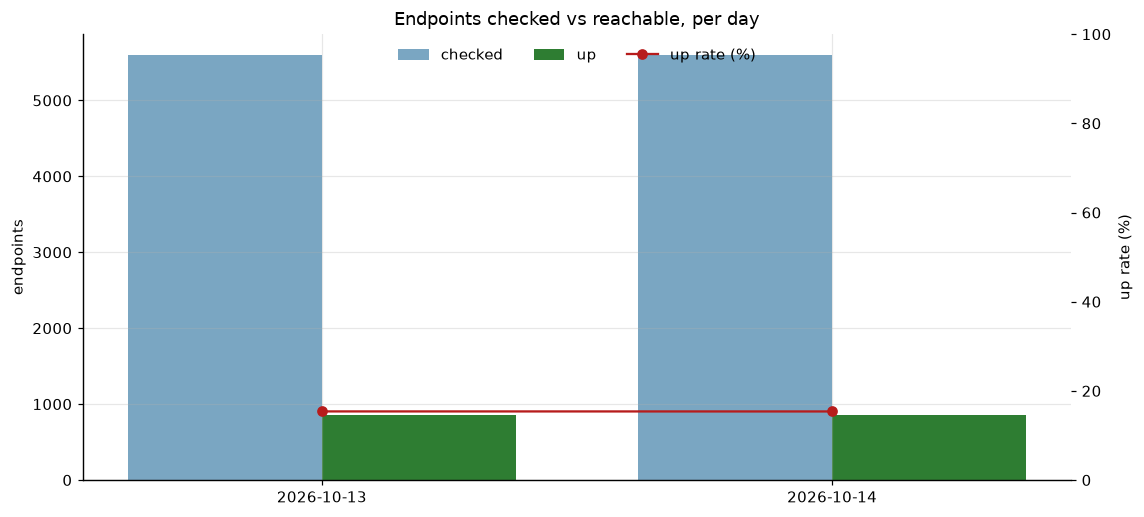

In [4]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = range(len(daily_latest))
w = 0.38
ax.bar([i - w / 2 for i in x], daily_latest["checked"], width=w, label="checked", color="#7aa6c2")
ax.bar([i + w / 2 for i in x], daily_latest["up"], width=w, label="up", color=GREEN)
ax.set_xticks(list(x))
ax.set_xticklabels(daily_latest["date"])
ax.set_ylabel("endpoints")
ax.set_title("Endpoints checked vs reachable, per day")

ax2 = ax.twinx()
ax2.plot(list(x), daily_latest["up_rate_%"], color=RED, marker="o", label="up rate (%)")
ax2.set_ylim(0, max(100, daily_latest["up_rate_%"].max() * 1.25))
ax2.set_ylabel("up rate (%)")
ax2.grid(False)
ax2.spines["top"].set_visible(False)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", frameon=False, ncols=3)
fig.tight_layout()
plt.show()

## 3 · Latency of reachable endpoints

TCP connect time in milliseconds (log scale — the spread runs from ~1 ms to tens of seconds).

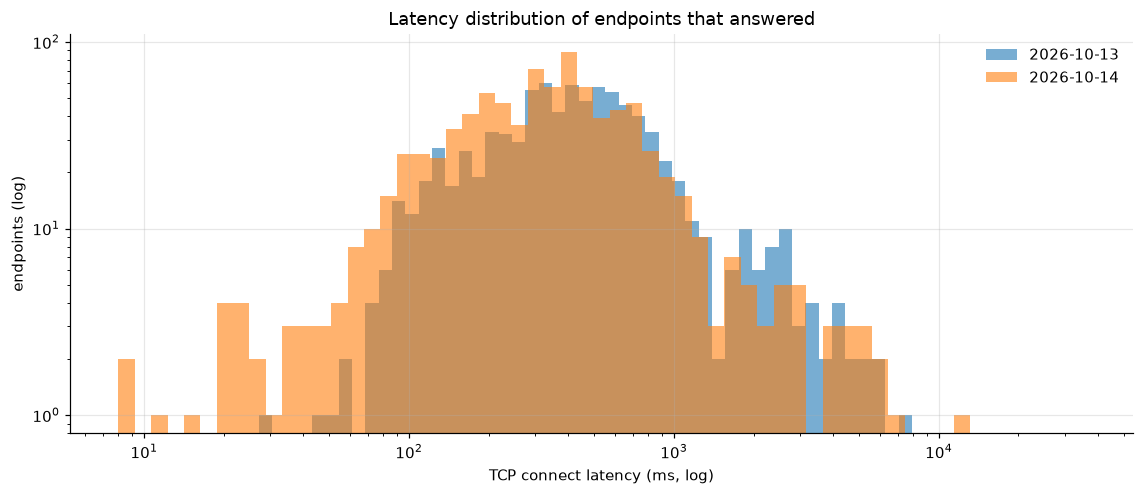

,count,mean,std,min,p50,p90,p99,max
date,,,,,,,,
2026-10-13,861.0,640.8,1121.7,27.1,413.3,1075.0,4402.2,25269.2
2026-10-14,860.0,549.8,1433.3,8.0,333.1,870.8,4554.1,35576.2


In [5]:
up = checks.loc[checks["status"] == "up"].copy()

fig, ax = plt.subplots()
for date, grp in up.groupby("date"):
    values = grp["latency_ms"].dropna()
    bins = np.logspace(np.log10(max(values.min(), 0.1)), np.log10(max(values.max(), 1)), 60)
    ax.hist(values, bins=bins, alpha=0.60, label=str(date))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("TCP connect latency (ms, log)")
ax.set_ylabel("endpoints (log)")
ax.set_title("Latency distribution of endpoints that answered")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

(up.groupby("date")["latency_ms"]
   .describe(percentiles=[0.50, 0.90, 0.99])
   .rename(columns={"50%": "p50", "90%": "p90", "99%": "p99"})
   .round(1))

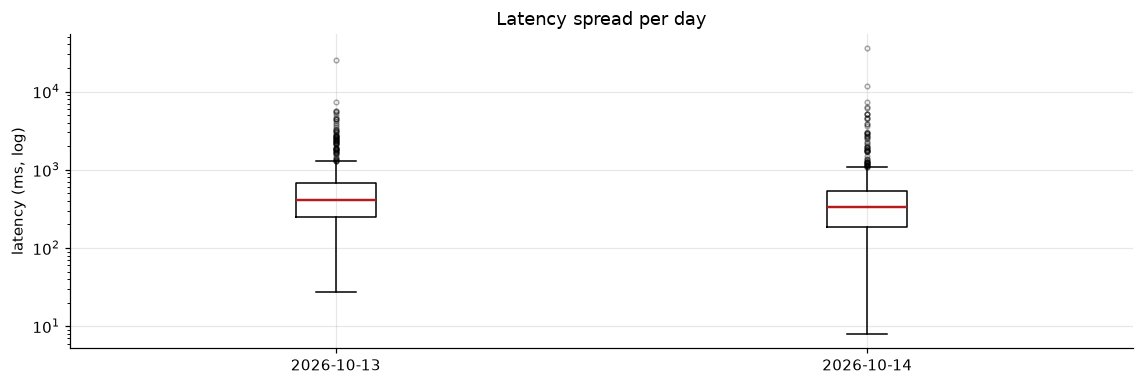

,date,host,latency_ms
0,2026-10-14,ftp.freebsd.org,8.011
1,2026-10-14,ftp.komkon.org,8.641
2,2026-10-14,ftp.fcc.gov,11.717
3,2026-10-14,ftp.umiacs.umd.edu,14.480
4,2026-10-14,nlmpubs.nlm.nih.gov,20.048
5,2026-10-14,ftp.columbia.edu,20.384
6,2026-10-14,ftp.ryerson.ca,20.930
7,2026-10-14,ftp.holistic-design.com,21.633
8,2026-10-14,ftp.siam.org,21.853
9,2026-10-14,ftp.nlm.nih.gov,21.857


In [6]:
fig, ax = plt.subplots(figsize=(10.5, 3.6))
data = [grp["latency_ms"].dropna() for _, grp in up.groupby("date")]
labels = [d for d, _ in up.groupby("date")]
ax.boxplot(data, tick_labels=labels, showfliers=True,
           flierprops={"markersize": 3, "alpha": 0.35}, medianprops={"color": RED, "linewidth": 1.6})
ax.set_yscale("log")
ax.set_ylabel("latency (ms, log)")
ax.set_title("Latency spread per day")
fig.tight_layout()
plt.show()

up.nsmallest(10, "latency_ms")[["date", "host", "latency_ms"]].reset_index(drop=True)

## 4 · Failure reasons

The legacy FTP list is full of dead hosts, so most checks are expected to fail.
`gaierror` = DNS name no longer resolves, `TimeoutError` = no answer in time,
`ConnectionRefusedError` = host alive but nothing listening on the port.

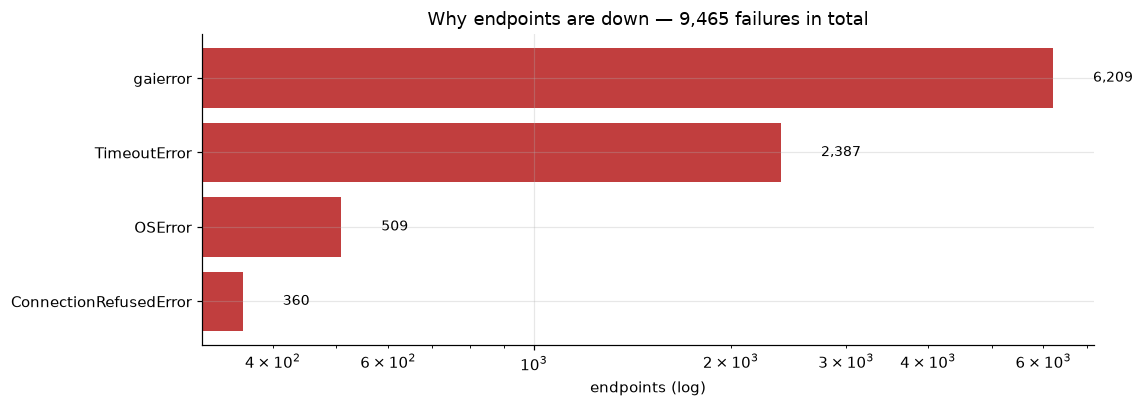

,error_type,error_message,endpoints
0,gaierror,[Errno -2] Name or service not known,5590
1,TimeoutError,timed out,2387
2,OSError,[Errno 101] Network is unreachable,507
3,ConnectionRefusedError,[Errno 111] Connection refused,360
4,gaierror,[Errno -3] Temporary failure in name resolution,350
5,gaierror,[Errno -5] No address associated with hostname,269
6,OSError,[Errno 22] Invalid argument,2


In [7]:
down = checks.loc[checks["status"] == "down"]
err_counts = down["error_type"].fillna("unknown").value_counts()

fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.barh(err_counts.index[::-1], err_counts.values[::-1], color=RED, alpha=0.85)
ax.set_xscale("log")
ax.set_xlabel("endpoints (log)")
ax.set_title(f"Why endpoints are down — {len(down):,} failures in total")
for i, v in enumerate(err_counts.values[::-1]):
    ax.text(v * 1.15, i, f"{v:,}", va="center", fontsize=9)
fig.tight_layout()
plt.show()

(down.groupby(["error_type", "error_message"], dropna=False).size()
    .rename("endpoints").reset_index()
    .sort_values("endpoints", ascending=False).head(12)
    .reset_index(drop=True))

## 5 · Root-directory listings — `reports/dir/*.json`

Every endpoint that answered TCP gets an anonymous FTP login and a root listing.
`status == ok` means the listing succeeded; `status == error` means the port was open but
login/listing failed (these are interesting — the server exists but is no longer a working FTP archive).

In [8]:
def _error_type(value):
    return value.get("type") if isinstance(value, dict) else value

listing_rows = []
for path in sorted(glob.glob(str(REPORTS / "dir" / "*.json"))):
    with open(path) as fh:
        d = json.load(fh)
    s = d.get("summary") or {}
    srv = d.get("server") or {}
    listing_rows.append({
        "host": d.get("host"),
        "status": d.get("status"),
        "error_type": _error_type(d.get("error")),
        "listing_method": d.get("listing_method"),
        "timestamps_timezone": d.get("timestamps_timezone"),
        "duration_ms": d.get("duration_ms"),
        "unparsed_lines": d.get("unparsed_lines"),
        "tcp_latency_ms": d.get("tcp_latency_ms"),
        "syst": srv.get("system"),
        "encoding": srv.get("encoding"),
        "features": srv.get("features") or [],
        "entries": s.get("entries"),
        "files": s.get("files"),
        "directories": s.get("directories"),
        "links": s.get("links"),
        "file_bytes": s.get("file_bytes"),
        "oldest_modified_at": s.get("oldest_modified_at"),
        "latest_modified_at": s.get("latest_modified_at"),
    })

listings = pd.DataFrame(listing_rows)
ok = listings.loc[listings["status"] == "ok"].copy()
print(f"{len(listings)} hosts tried a listing — {len(ok)} ok, {(listings['status'] == 'error').sum()} failed")
listings.head()

860 hosts tried a listing — 401 ok, 459 failed


,host,status,error_type,listing_method,timestamps_timezone,duration_ms,unparsed_lines,tcp_latency_ms,syst,encoding,features,entries,files,directories,links,file_bytes,oldest_modified_at,latest_modified_at
0,aeneas.mit.edu,error,TimeoutError,NaN,NaN,30359.544,0,126.549,NaN,NaN,[],0,0,0,0,0,NaN,NaN
1,alpha.greenie.net,ok,NaN,list,server-local,1976.950,0,239.437,UNIX Type: L8,utf-8,"[EPRT, EPSV, MDTM, PASV, REST, SIZE, TVFS, UTF8]",1,0,1,0,0,2006-03-10T00:00:00,2006-03-10T00:00:00
2,athena-dist.mit.edu,error,TimeoutError,NaN,NaN,30391.969,0,46.031,NaN,NaN,[],0,0,0,0,0,NaN,NaN
3,c64.rulez.org,ok,NaN,mlsd,utc,1773.604,0,232.296,UNIX Type: L8,utf-8,"[CLNT, CSID, EPRT, EPSV, HOST, LANG, MDTM, MFF...",1,0,1,0,0,2009-03-10T21:38:17Z,2009-03-10T21:38:17Z
4,candc1.golden.net,error,TimeoutError,NaN,NaN,45486.813,0,130.294,NaN,NaN,[],0,0,0,0,0,NaN,NaN


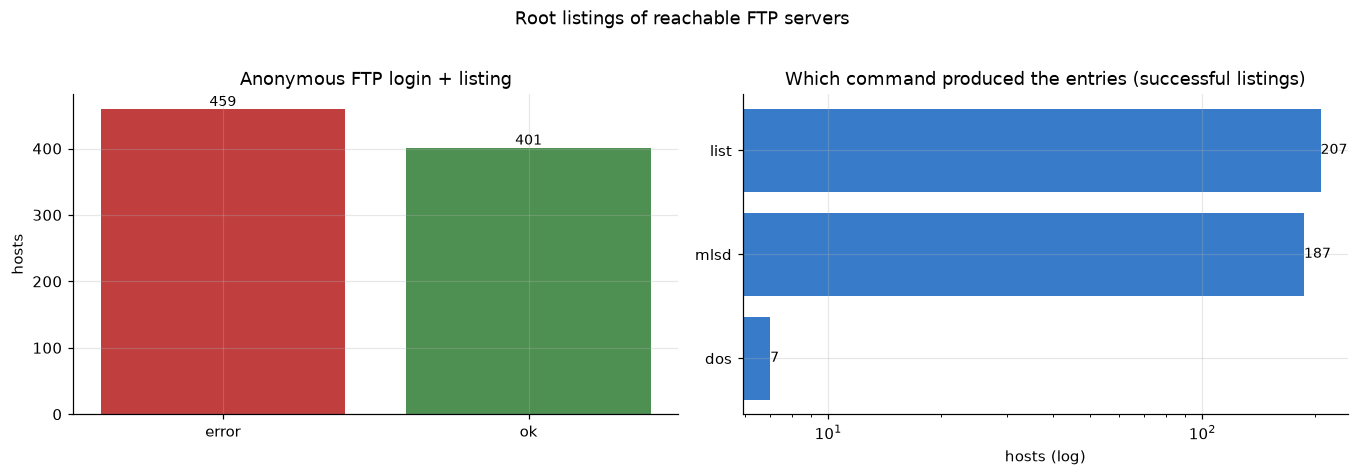

,hosts
timestamps_timezone,
server-local,214
utc,187


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2))

status_counts = listings["status"].value_counts()
colors = [GREEN if s == "ok" else RED for s in status_counts.index]
bars = ax1.bar(status_counts.index, status_counts.values, color=colors, alpha=0.85)
ax1.bar_label(bars, fontsize=9)
ax1.set_title("Anonymous FTP login + listing")
ax1.set_ylabel("hosts")

method = ok["listing_method"].fillna("n/a").value_counts()
bars = ax2.barh(method.index[::-1], method.values[::-1], color=BLUE, alpha=0.85)
ax2.bar_label(bars, fontsize=9)
ax2.set_xscale("log")
ax2.set_title("Which command produced the entries (successful listings)")
ax2.set_xlabel("hosts (log)")

fig.suptitle("Root listings of reachable FTP servers", y=1.02)
fig.tight_layout()
plt.show()

ok["timestamps_timezone"].value_counts().rename("hosts").to_frame()

### How long a listing takes, and how much the roots hold

Both axes are log-scaled: most archives list in well under a second, a few take up to ~50 s
and expose tens of GB in their root directory.

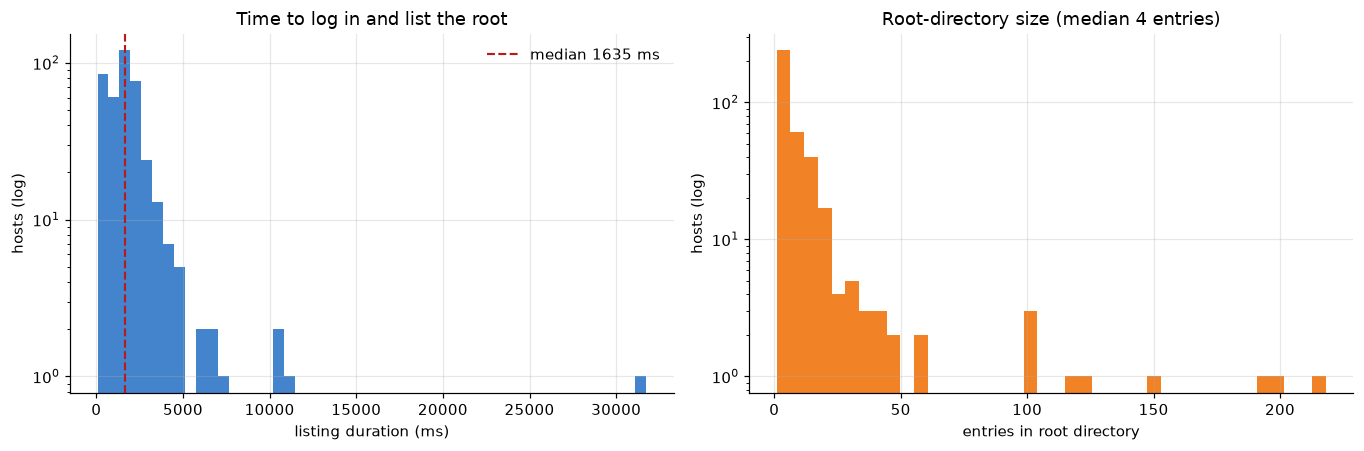

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2))

durations = ok["duration_ms"].dropna()
ax1.hist(durations, bins=50, color=BLUE, alpha=0.80)
ax1.axvline(durations.median(), color=RED, linestyle="--", linewidth=1.4,
            label=f"median {durations.median():.0f} ms")
ax1.set_yscale("log")
ax1.set_xlabel("listing duration (ms)")
ax1.set_ylabel("hosts (log)")
ax1.set_title("Time to log in and list the root")
ax1.legend(frameon=False)

entry_counts = ok.loc[ok["entries"] > 0, "entries"]
ax2.hist(entry_counts, bins=40, color=ORANGE, alpha=0.85)
ax2.set_yscale("log")
ax2.set_xlabel("entries in root directory")
ax2.set_ylabel("hosts (log)")
ax2.set_title(f"Root-directory size (median {entry_counts.median():.0f} entries)")

fig.tight_layout()
plt.show()

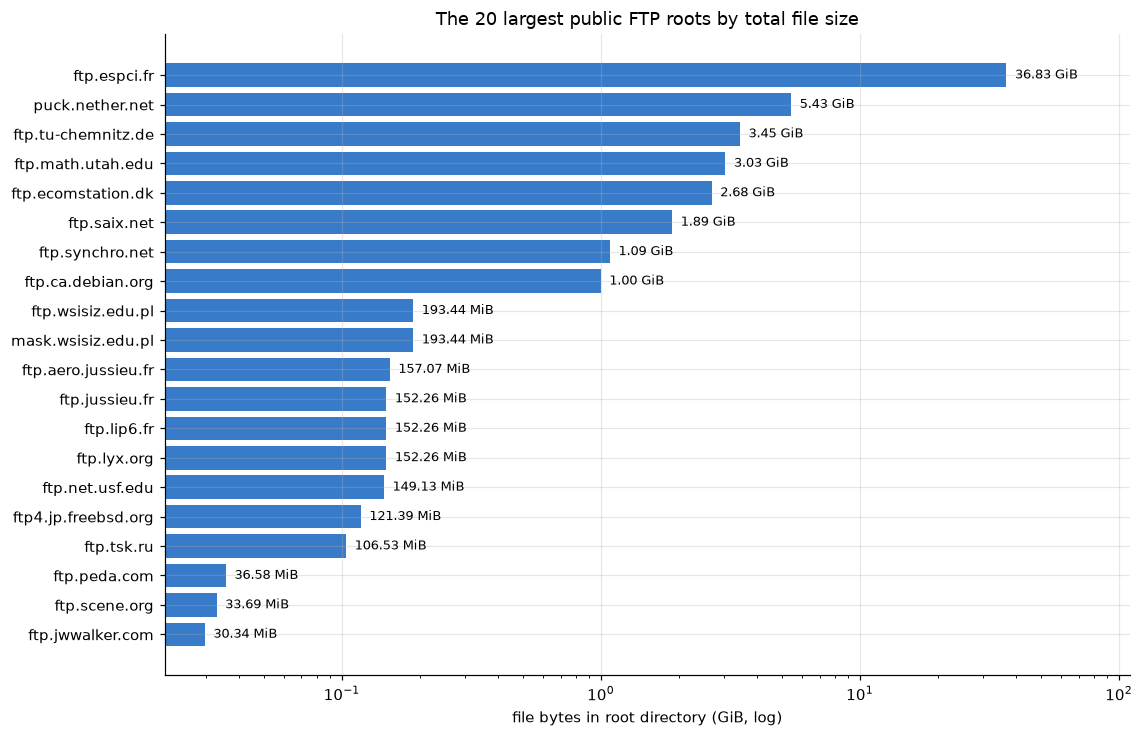

,host,entries,files,directories,file_bytes,listing_method,latest_modified_at
0,ftp.espci.fr,13,4,9,36.83 GiB,mlsd,2026-10-13T08:41:37Z
1,puck.nether.net,8,5,2,5.43 GiB,list,2025-09-13T00:00:00
2,ftp.tu-chemnitz.de,3,1,2,3.45 GiB,list,2026-10-14T03:42:00
3,ftp.math.utah.edu,44,28,9,3.03 GiB,list,2026-10-12T23:50:00
4,ftp.ecomstation.dk,7,4,3,2.68 GiB,list,2026-01-27T00:00:00
5,ftp.saix.net,4,3,1,1.89 GiB,mlsd,2026-10-13T19:43:25Z
6,ftp.synchro.net,102,100,2,1.09 GiB,mlsd,2026-10-13T13:25:27Z
7,ftp.ca.debian.org,20,3,14,1.00 GiB,list,2026-10-14T02:02:00
8,ftp.wsisiz.edu.pl,5,3,2,193.44 MiB,mlsd,2026-10-14T01:35:08Z
9,mask.wsisiz.edu.pl,5,3,2,193.44 MiB,mlsd,2026-10-14T01:35:08Z


In [11]:
big = ok.dropna(subset=["file_bytes"]).nlargest(20, "file_bytes").iloc[::-1]

fig, ax = plt.subplots(figsize=(10.5, 6.8))
bars = ax.barh(big["host"], big["file_bytes"] / 1024 ** 3, color=BLUE, alpha=0.85)
ax.set_xscale("log")
ax.set_xlabel("file bytes in root directory (GiB, log)")
ax.set_title("The 20 largest public FTP roots by total file size")
for bar, (_, row) in zip(bars, big.iterrows()):
    ax.text(bar.get_width() * 1.08, bar.get_y() + bar.get_height() / 2,
            human_bytes(row["file_bytes"]), va="center", fontsize=8.5)
ax.set_xlim(right=big["file_bytes"].max() / 1024 ** 3 * 3)
fig.tight_layout()
plt.show()

pretty = big.iloc[::-1][["host", "entries", "files", "directories", "file_bytes", "listing_method", "latest_modified_at"]].copy()
pretty["file_bytes"] = pretty["file_bytes"].map(human_bytes)
pretty.reset_index(drop=True)

### Server capabilities — most common `FEAT` replies

The `FEAT` command tells us which RFC 3659 extensions each server advertises.

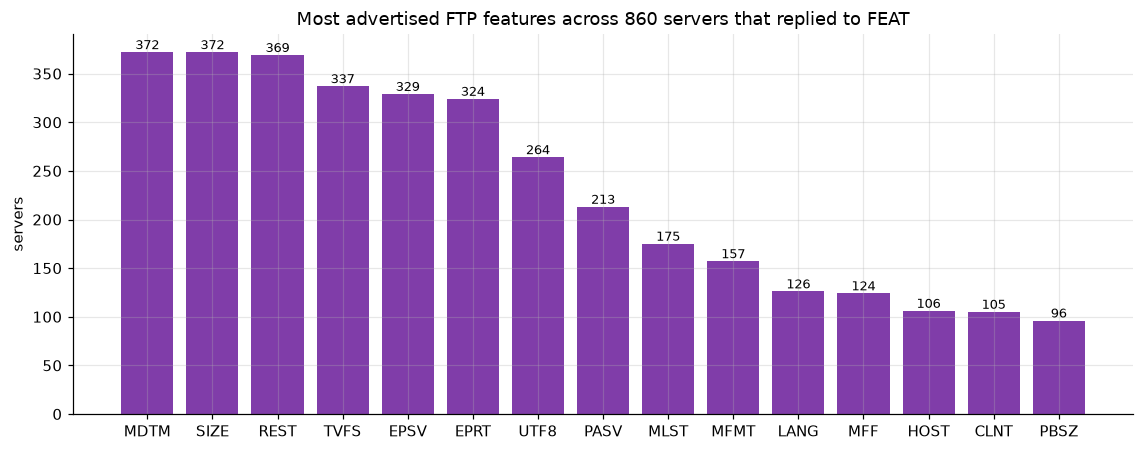

,servers
feature,
MDTM,372
SIZE,372
REST,369
TVFS,337
EPSV,329
EPRT,324
UTF8,264
PASV,213
MLST,175


In [12]:
feat = listings.explode("features")
feat["feature"] = feat["features"].astype("string").str.upper().str.split().str[0]
feat_counts = feat["feature"].dropna().value_counts().head(15)

fig, ax = plt.subplots(figsize=(10.5, 4.2))
bars = ax.bar(feat_counts.index, feat_counts.values, color=PURPLE, alpha=0.85)
ax.bar_label(bars, fontsize=8.5)
ax.set_ylabel("servers")
ax.set_title(f"Most advertised FTP features across {feat['host'].nunique()} servers that replied to FEAT")
fig.tight_layout()
plt.show()

feat_counts.rename("servers").to_frame()

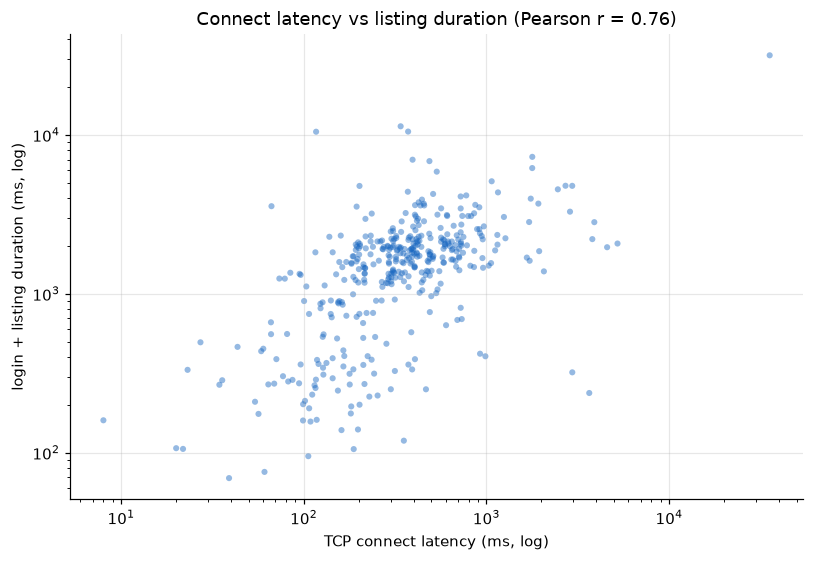

,hosts
error_type,
error_perm,379
TimeoutError,39
error_temp,9
ConnectionResetError,9
EOFError,9
UnicodeDecodeError,6
ConnectionRefusedError,4
OSError,2
error_proto,1


In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.scatter(ok["tcp_latency_ms"], ok["duration_ms"], s=16, alpha=0.45, color=BLUE, edgecolors="none")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("TCP connect latency (ms, log)")
ax.set_ylabel("login + listing duration (ms, log)")
corr = ok[["tcp_latency_ms", "duration_ms"]].corr().iloc[0, 1]
ax.set_title(f"Connect latency vs listing duration (Pearson r = {corr:.2f})")
fig.tight_layout()
plt.show()

(listings.loc[listings["status"] == "error"]
    .assign(error_type=lambda df: df["error_type"].fillna("unknown"))
    .groupby("error_type").size().rename("hosts")
    .sort_values(ascending=False).to_frame())

## 6 · Freshest content

Roots whose newest entry has the most recent `modify` timestamp — the archives that are
still being maintained.

In [14]:
fresh = (ok.dropna(subset=["latest_modified_at"])
           .sort_values("latest_modified_at", ascending=False)
           .head(15)[["host", "entries", "file_bytes", "latest_modified_at", "timestamps_timezone"]])
fresh["file_bytes"] = fresh["file_bytes"].map(human_bytes)
fresh.reset_index(drop=True)

,host,entries,file_bytes,latest_modified_at,timestamps_timezone
0,ftp.bg.freebsd.org,30,0 B,2026-10-14T06:44:00,server-local
1,ftp-stud.fht-esslingen.de,23,2.96 KiB,2026-10-14T05:43:00,server-local
2,ftp.fr.debian.org,7,0 B,2026-10-14T05:18:00,server-local
3,ftp.sra.co.jp,10,22.77 MiB,2026-10-14T03:44:01Z,utc
4,ftp.tu-chemnitz.de,3,3.45 GiB,2026-10-14T03:42:00,server-local
5,ftp.mplayerhq.hu,8,0 B,2026-10-14T03:38:00,server-local
6,ftp.cubic.org,4,57.42 KiB,2026-10-14T03:37:06Z,utc
7,ftp.swin.edu.au,29,0 B,2026-10-14T03:22:00Z,utc
8,ftp.helion.pl,10,133 B,2026-10-14T03:07:44Z,utc
9,ftp.blarg.net,2,188 B,2026-10-14T03:01:02Z,utc


## 7 · Drill into a single host

`show_host(<host>)` prints everything the run recorded about one FTP server and previews its
root entries. Try any host from the tables above.

In [15]:
def show_host(host, max_entries=20):
    """Pretty-print the directory report of a single host."""
    path = REPORTS / "dir" / f"{host}.json"
    if not path.exists():
        print(f"No directory report for {host!r} (looked at {path}).")
        return
    with open(path) as fh:
        d = json.load(fh)
    srv = d.get("server") or {}
    root = d.get("root") or {}
    s = d.get("summary") or {}

    print(f"ftp://{host}/ — status: {d.get('status')}   (checked {d.get('checked_at')})")
    print(f"  greeting       : {srv.get('welcome')}")
    print(f"  login response : {srv.get('login_response')}")
    print(f"  SYST           : {srv.get('system')}")
    print(f"  features       : {', '.join(srv.get('features') or [])}")
    print(f"  listing        : method={d.get('listing_method')}  tz={d.get('timestamps_timezone')}  "
          f"duration={d.get('duration_ms')} ms  unparsed_lines={d.get('unparsed_lines')}")
    if root:
        print(f"  root dir       : mode={root.get('mode')}  owner={root.get('created_by')}:{root.get('group')}  "
              f"modified={root.get('modified_at')}")
    print(f"  summary        : {s.get('entries')} entries ({s.get('files')} files, {s.get('directories')} dirs, "
          f"{s.get('links')} links), {human_bytes(s.get('file_bytes'))} of files")
    if d.get("error"):
        print(f"  error          : {d.get('error')}")

    entries = pd.DataFrame(d.get("entries") or [])
    if entries.empty:
        print("  (no entries listed)")
        return
    cols = [c for c in ("name", "type", "size", "modified_at", "permissions", "group") if c in entries.columns]
    preview = entries[cols].head(max_entries).copy()
    if "size" in preview.columns:
        preview["size"] = preview["size"].map(human_bytes)
    return preview


show_host(listings.loc[listings["entries"].idxmax(), "host"])

ftp://ftp.draytek.com/ — status: ok   (checked 2026-10-14T03:40:41.385Z)
  greeting       : 220 ProFTPD Server (ProFTPD Default Server) [::ffff:62.116.169.188]
  login response : Anonymous access granted, restrictions apply
  SYST           : UNIX Type: L8
  features       : AUTH, CCC, CLNT, CSID, EPRT, EPSV, HOST, LANG, MDTM, MFF, MFMT, MLST, PBSZ, PROT, RANG, REST, SIZE, SSCN, TVFS, UTF8
  listing        : method=mlsd  tz=utc  duration=1825.98 ms  unparsed_lines=0
  root dir       : mode=0777  owner=0:0  modified=2026-10-08T01:27:56Z
  summary        : 218 entries (0 files, 218 dirs, 0 links), 0 B of files


,name,type,size,modified_at,permissions,group
0,ESG,directory,—,2025-08-25T06:56:30Z,drwxrwxr-x,516
1,ACS SI,directory,—,2015-08-26T09:44:35Z,drwxrwxrwx,21
2,Vigor2600Ge,directory,—,2016-06-07T07:46:35Z,drwxrwxr-x,21
3,Vigor2867,directory,—,2026-06-05T05:42:13Z,drwxrwxr-x,516
4,VigorSwitch G1280,directory,—,2017-12-19T03:53:20Z,drwxrwxr-x,21
5,Vigor2100,directory,—,2016-06-07T07:42:50Z,drwxrwxr-x,21
6,Vigor2960,directory,—,2015-12-17T02:52:07Z,drwxrwxr-x,21
7,Vigor3100,directory,—,2016-06-07T07:47:25Z,drwxrwxr-x,21
8,Vigor2820,directory,—,2016-06-07T07:47:00Z,drwxrwxr-x,21
9,VigorAP 807,directory,—,2026-09-30T07:24:58Z,drwxrwxr-x,516


## 8 · Snapshot summary

In [16]:
total_bytes = ok["file_bytes"].dropna().sum()
print("FTPing — current snapshot")
print(f"  days with data               : {checks['date'].nunique()}")
print(f"  endpoint checks              : {len(checks):,}")
print(f"  endpoints that answered      : {len(up):,}  ({len(up) / len(checks) * 100:.1f}% of all checks)")
print(f"  unique hosts ever reachable  : {up['host'].nunique():,}")
print(f"  root listings attempted      : {len(listings):,}  (ok: {len(ok)}, failed: {(listings['status'] == 'error').sum()})")
print(f"  total file bytes advertised  : {human_bytes(total_bytes)} across {ok['entries'].sum():,} root entries")
print(f"  most common failure          : {down['error_type'].fillna('unknown').value_counts().index[0]} "
      f"({down['error_type'].fillna('unknown').value_counts().iloc[0]:,} endpoints)")

FTPing — current snapshot
  days with data               : 2
  endpoint checks              : 11,186
  endpoints that answered      : 1,721  (15.4% of all checks)
  unique hosts ever reachable  : 866
  root listings attempted      : 860  (ok: 401, failed: 459)
  total file bytes advertised  : 56.98 GiB across 4,136 root entries
  most common failure          : gaierror (6,209 endpoints)


### Notes

- Outputs (tables and the embedded chart images above) are **kept in this file on purpose** —
  do not clear them; they are the rendered report.
- Refresh everything after a new daily run with *Restart & Run All* (or
  `jupyter nbconvert --to notebook --execute --inplace ftping_analysis.ipynb`).
- The notebook only needs `pandas`, `matplotlib` and `numpy`; it reads whatever is currently
  under `reports/`, so nothing here has to be updated when a new date appears.